# Simulate a frame the same size as your data

**What this does:** opens one raw TIFF frame, splits it into left and right channels, and simulates a single frame with the same height and width as one channel. Run the cells in order using the **Python (DECODE Intel)** kernel. Your TIFF is read only.

The simulation uses DECODE’s example PSF and camera settings, not a calibration of your Nanoimager. Its aim is to explore the workflow and parameters.


In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tifffile
import torch
import decode.utils.param_io
from decode.neuralfitter.train.random_simulation import setup_random_simulation

# Works if VS Code starts the notebook in mphys/ or decode_walkthrough/.
project = Path.cwd().resolve()
if not (project / 'experimental_data_workflow').is_dir():
    project = project.parent
if not (project / 'experimental_data_workflow').is_dir():
    raise FileNotFoundError('Open the notebook from the mphys project folder.')
print('Project folder:', project)


Project folder: /Users/rohan/Documents/projects/mphys


## 1. Choose and inspect your frame

The code below chooses the first TIFF in `data/low_density_examples`. To choose another movie, replace the `movie_path` line as shown in its comment. `frame_index = 0` means the first frame. The two images use the same contrast scale.


Movie: corrected.tif | Number of frames: 1826
Full frame: (684, 856); one channel: 684 × 428 pixels


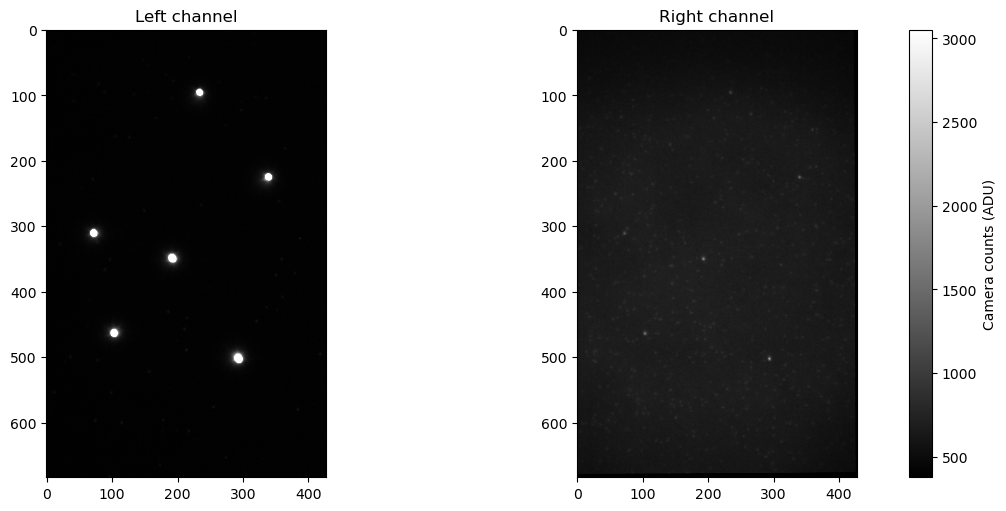

In [14]:
# To use another recording, replace this line, for example:
# movie_path = project / 'data/high_density_examples/YOUR_FILE.tif'
movie_path = project / "data/preprocessed_data/corrected.tif"
frame_index = 0

with tifffile.TiffFile(movie_path) as tif:
    raw = tif.pages[frame_index].asarray()
    print('Movie:', movie_path.name, '| Number of frames:', len(tif.pages))

if raw.ndim != 2 or raw.shape[1] % 2:
    raise ValueError('Expected one grayscale frame containing two equal-width channels.')
left, right = np.split(raw, 2, axis=1)
height, width = left.shape
print(f'Full frame: {raw.shape}; one channel: {height} × {width} pixels')

low, high = np.percentile(raw, [1, 99.9])
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, image, name in zip(axes, (left, right), ('Left channel', 'Right channel')):
    im = ax.imshow(image, cmap='gray', vmin=low, vmax=high)
    ax.set_title(name)
fig.colorbar(im, ax=axes, label='Camera counts (ADU)')
plt.show()


## 2. Set the simulation values

Change the values below and rerun this cell and the next one. `emitters_per_frame` is the average for the **whole simulated channel**, not per pixel. Background and brightness use DECODE’s simulated photon convention. These starting values are just for exploration, not measurements of your recording.

A larger frame with many emitters is slower on the CPU. Start small and increase the emitter count gradually.


In [51]:
emitters_per_frame = 1000
background_photons = [0, 1]  # Uniform range: one background value sampled per frame
brightness_mean_std = [774.5, 100.27]  # Mean and standard deviation of emitter brightness
seed = 67

# The example parameters and PSF belong together; these are NOT your microscope calibration.
example = project / 'experimental_data_workflow'
param = decode.utils.param_io.load_params(str(example / 'param_run.yaml'))
param.InOut.calibration_file = str(example / 'spline_calibration_3dcal.mat')
param.Hardware.device = 'cpu'
param.Hardware.device_simulation = 'cpu'
param.Simulation.emitter_av = emitters_per_frame
param.Simulation.bg_uniform = background_photons
param.Simulation.intensity_mu_sig = brightness_mean_std
param.Camera.px_size = [117.0, 117.0]  # nm/pixel; confirmed in your .nim files
param.Camera.baseline = 100.0           # ADU; normal-readout nominal offset
param.Camera.e_per_adu = 0.46          # electrons per camera count
param.Camera.em_gain = None           # sCMOS, no EM multiplication
param.Camera.read_sigma = 1.6           # electrons RMS; standard scan
param.Camera.qe = 0.8                   # use detected-photon equivalents
param.Camera.spur_noise = 0.0           # simplifying assumption, not a measured value
param.Camera.convert2photons = True

# Match one channel's dimensions, not the full side-by-side camera frame.
param.Simulation.img_size = [height, width]
param.Simulation.emitter_extent[0] = [-0.5, height - 0.5]
param.Simulation.emitter_extent[1] = [-0.5, width - 0.5]
param.Simulation.psf_extent[0] = [-0.5, height - 0.5]
param.Simulation.psf_extent[1] = [-0.5, width - 0.5]
param.HyperParameter.pseudo_ds_size = 0  # DECODE uses inclusive frame indices: 0 to 0
param.TestSet.test_size = 0

torch.manual_seed(seed)
np.random.seed(seed)
print('Simulation size:', param.Simulation.img_size, '| Average emitters:', emitters_per_frame)


Simulation size: [684, 428] | Average emitters: 1000


## 3. Generate and display one simulated frame

The result has the same **pixel dimensions** as one channel. Its pixel values are in DECODE’s converted photon units, whereas the raw TIFF uses camera counts (ADU), so their colour scales should not be compared numerically without camera calibration.


Simulated frame shape: (684, 428)


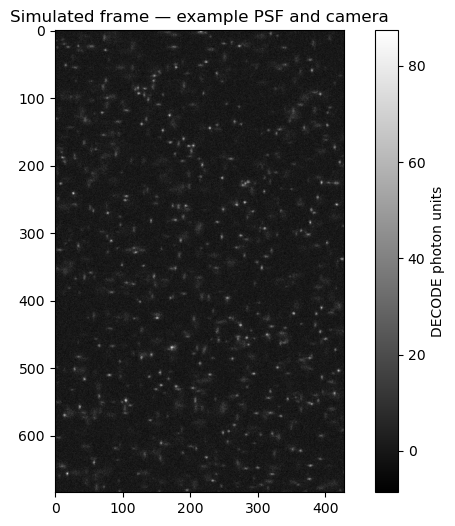

In [52]:
simulator, _ = setup_random_simulation(param)
emitters, simulated_frames, backgrounds = simulator.sample()
simulated_frame = simulated_frames[0].detach().cpu().numpy()
print('Simulated frame shape:', simulated_frame.shape)

plt.figure(figsize=(8, 6))
plt.imshow(simulated_frame, cmap='gray')
plt.title('Simulated frame — example PSF and camera')
plt.colorbar(label='DECODE photon units')
plt.show()


The physical pixel size in nanometres, the microscope PSF and the camera settings are separate from the image dimensions. Matching the frame size alone does not calibrate the simulation. See `02_psf_calibration.ipynb` for what to ask the data collector.
